# Lab #7
Name: Maan Abdullah Alghamdi  
ID: 2240001433  
Course: ARTI 403 - Image Processing
## Part B - Mathematical and Statistical Filters
I completed this notebook using the supplied images. I run the cells in order
from a fresh kernel. All image paths are relative to the notebook folder.

## Setup

In [1]:
from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def load_gray(name):
    path = Path(name)
    if not path.is_file():
        raise FileNotFoundError(f"Keep {name} beside this notebook: {Path.cwd()}")
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not decode {path}")
    return image

def to_uint8(values):
    return np.rint(np.clip(values, 0, 255)).astype(np.uint8)

def show_images(images, titles, cols=2):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(10, 3.5 * rows), squeeze=False)
    for ax, image, label in zip(axes.flat, images, titles):
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        ax.set_title(label)
        ax.axis('off')
    for ax in axes.flat[len(images):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print(f"Python {sys.version.split()[0]} | OpenCV {cv2.__version__}")
print(f"NumPy {np.__version__}")

Python 3.12.10 | OpenCV 5.0.0
NumPy 2.5.2


## B1. Reproducible noise generation
I use noise.jpg as the supplied reference for adding synthetic noise. Its filename
does not guarantee that it is originally noise-free. Gaussian noise has standard
deviation 25.5 intensity levels; exponential noise has scale 10; uniform noise
spans -20 to 20. I replace exactly 4% (rounded) of pixel positions for mixed
salt-and-pepper noise, without duplicates. A fixed seed reproduces my results.

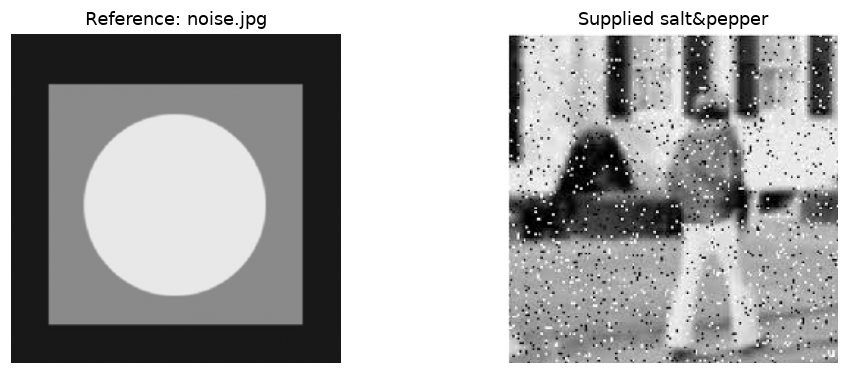

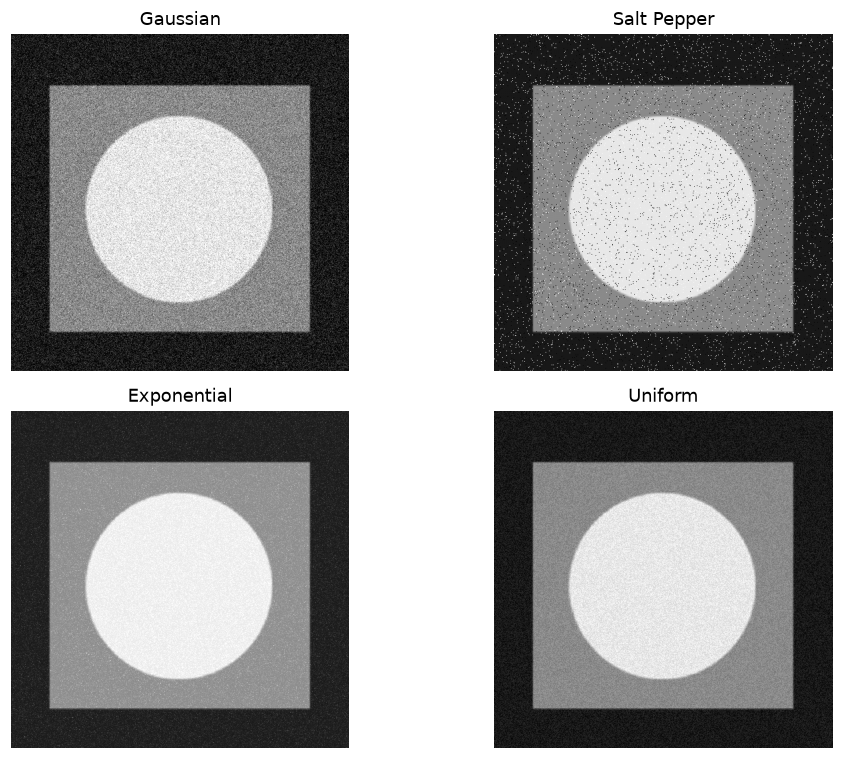

In [2]:
reference = load_gray('noise.jpg')
supplied_sp = load_gray('salt&Pepper.jpg')

def add_noise(image, noise_type, rng):
    x = image.astype(np.float64)
    if noise_type == 'gaussian':
        return to_uint8(x + rng.normal(0, 25.5, image.shape))
    if noise_type == 'exponential':
        return to_uint8(x + rng.exponential(10.0, image.shape))
    if noise_type == 'uniform':
        return to_uint8(x + rng.uniform(-20, 20, image.shape))
    if noise_type in ('salt_pepper', 'salt', 'pepper'):
        result = image.copy()
        count = round(0.04 * image.size)
        indices = rng.choice(image.size, count, replace=False)
        if noise_type == 'salt_pepper':
            split = count // 2
            result.flat[indices[:split]] = 255
            result.flat[indices[split:]] = 0
        else:
            result.flat[indices] = 255 if noise_type == 'salt' else 0
        return result
    raise ValueError(f'Unknown noise type: {noise_type}')

rng = np.random.default_rng(2240001433)
noise_names = ['gaussian', 'salt_pepper', 'exponential', 'uniform']
noisy = {name: add_noise(reference, name, rng) for name in noise_names}
salt_only = add_noise(reference, 'salt', rng)
pepper_only = add_noise(reference, 'pepper', rng)
show_images([reference, supplied_sp], ['Reference: noise.jpg', 'Supplied salt&pepper'])
show_images(list(noisy.values()), [n.replace('_', ' ').title() for n in noise_names])

## B2. Arithmetic mean: built-in and manual
I average a 3 x 3 neighbourhood using cv2.blur and a normalized all-ones kernel.
Both methods process the same Gaussian-noisy image with the same reflected border.
I retain floating-point values until the final rounding to avoid intermediate loss.

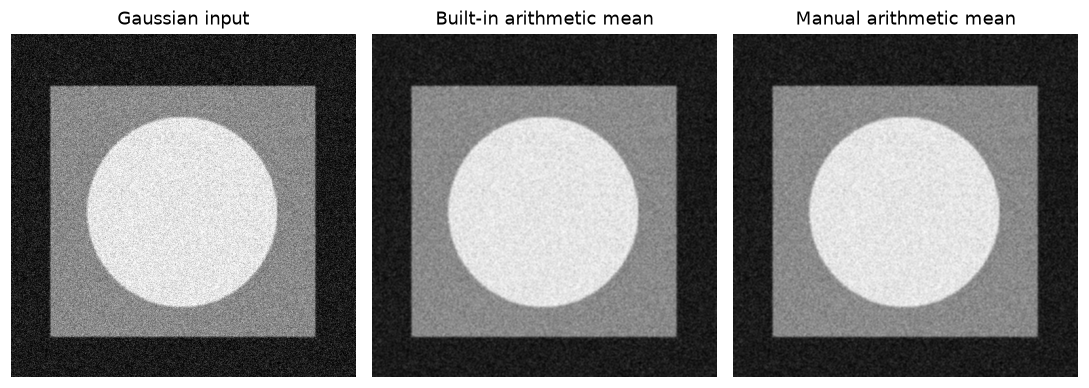

Maximum float difference: 8.526512829121202e-14


In [3]:
BORDER = cv2.BORDER_REFLECT_101

def check_size(size):
    if not isinstance(size, int) or size < 1 or size % 2 == 0:
        raise ValueError('Kernel size must be a positive odd integer.')

def local_mean(x, size=3):
    check_size(size)
    return cv2.blur(x.astype(np.float64), (size, size), borderType=BORDER)

def arithmetic_mean(image, size=3):
    return to_uint8(local_mean(image, size))

kernel = np.ones((3, 3), np.float64) / 9
mean_builtin_float = local_mean(noisy['gaussian'])
mean_manual_float = cv2.filter2D(
    noisy['gaussian'].astype(np.float64), -1, kernel, borderType=BORDER)
mean_manual = to_uint8(mean_manual_float)
show_images([noisy['gaussian'], arithmetic_mean(noisy['gaussian']), mean_manual],
            ['Gaussian input', 'Built-in arithmetic mean', 'Manual arithmetic mean'], 3)
print('Maximum float difference:',
      np.max(np.abs(mean_builtin_float - mean_manual_float)))

## B3. Geometric mean
I compute exp(mean(log(x))) over each window. If any value is zero, the
geometric mean is exactly zero. I detect these windows explicitly instead of
letting log(0) create infinities. This mean can preserve detail differently from
the arithmetic mean, but black impulses reduce it strongly.

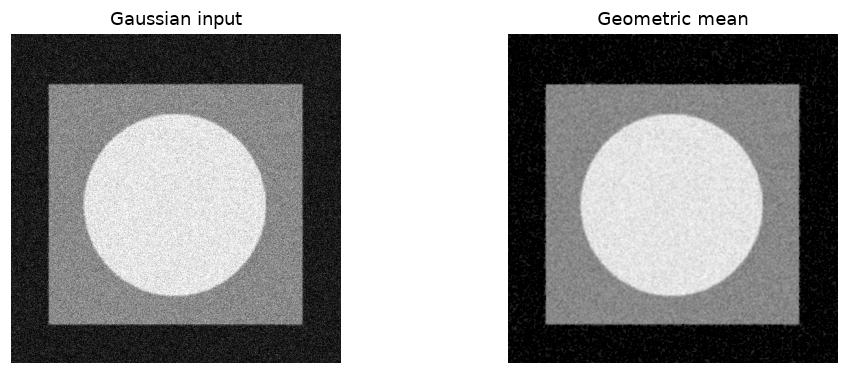

In [4]:
def zero_windows(image, size):
    return local_mean((image == 0).astype(np.float64), size) > 0

def geometric_mean_filter(image, kernel_size=3):
    x = image.astype(np.float64)
    safe = np.maximum(x, 1.0)
    result = np.exp(local_mean(np.log(safe), kernel_size))
    result[zero_windows(image, kernel_size)] = 0
    return to_uint8(result)

show_images([noisy['gaussian'], geometric_mean_filter(noisy['gaussian'])],
            ['Gaussian input', 'Geometric mean'])

## B4. Harmonic mean
I calculate 1 / mean(1/x), equivalent to n / sum(1/x). A window containing
zero has the limiting harmonic mean zero. The filter suppresses bright salt
impulses, but it is sensitive to pepper noise. I demonstrate it on salt-only noise.

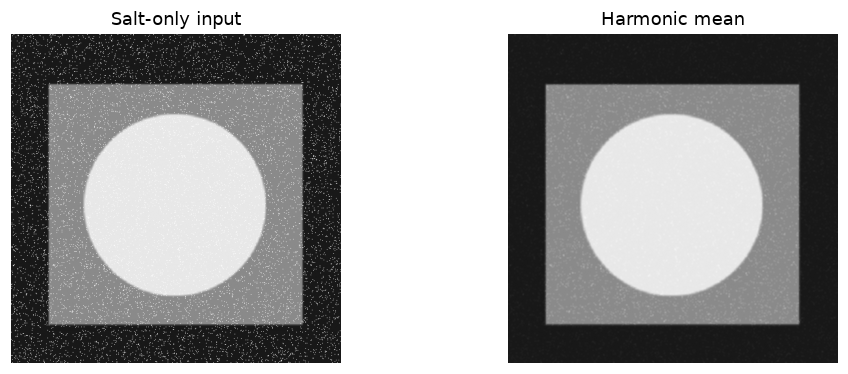

In [5]:
def harmonic_mean_filter(image, kernel_size=3):
    x = image.astype(np.float64)
    reciprocal_mean = local_mean(1.0 / np.maximum(x, 1.0), kernel_size)
    result = 1.0 / reciprocal_mean
    result[zero_windows(image, kernel_size)] = 0
    return to_uint8(result)

show_images([salt_only, harmonic_mean_filter(salt_only)],
            ['Salt-only input', 'Harmonic mean'])

## B5. Contraharmonic mean
I use sum(x^(Q+1)) / sum(x^Q). Positive Q suppresses pepper; negative Q
suppresses salt. I use separate impulse inputs to show the effect of each sign.
For Q < 0, I use a small positive floor for zero intensities because negative
powers of zero are undefined. Q=0 is the arithmetic mean; Q=-1 uses the exact
harmonic limiting convention. A single Q does not remove both impulse types.

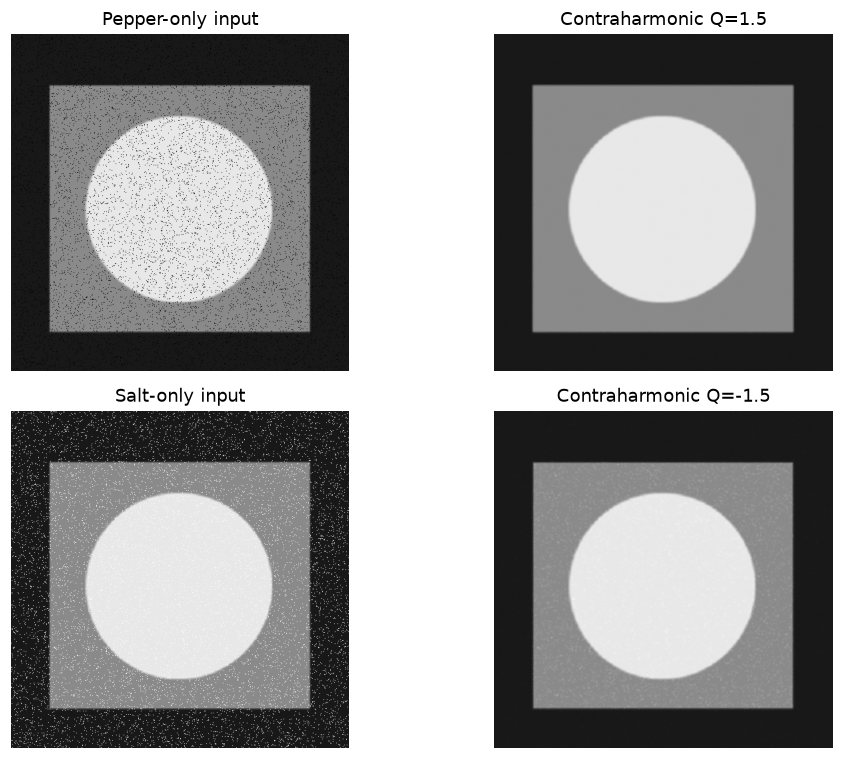

In [6]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    check_size(kernel_size)
    if not np.isfinite(Q) or abs(Q) > 5:
        raise ValueError('Use a finite Q between -5 and 5.')
    if Q == 0:
        return arithmetic_mean(image, kernel_size)
    if Q == -1:
        return harmonic_mean_filter(image, kernel_size)
    x = image.astype(np.float64)
    if Q < 0:
        x = np.maximum(x, 1e-6)
    numerator = local_mean(x ** (Q + 1), kernel_size)
    denominator = local_mean(x ** Q, kernel_size)
    result = np.divide(numerator, denominator, out=np.zeros_like(numerator),
                       where=denominator > 0)
    return to_uint8(result)

show_images([pepper_only, contra_harmonic_mean(pepper_only, Q=1.5),
             salt_only, contra_harmonic_mean(salt_only, Q=-1.5)],
            ['Pepper-only input', 'Contraharmonic Q=1.5',
             'Salt-only input', 'Contraharmonic Q=-1.5'])

## B6. Median filter
I use a 3 x 3 median on mixed salt-and-pepper noise and on the supplied impulse
image. The median rejects isolated extreme pixels while preserving edges better
than simple averaging in many impulse-noise cases. Larger impulse clusters can remain.

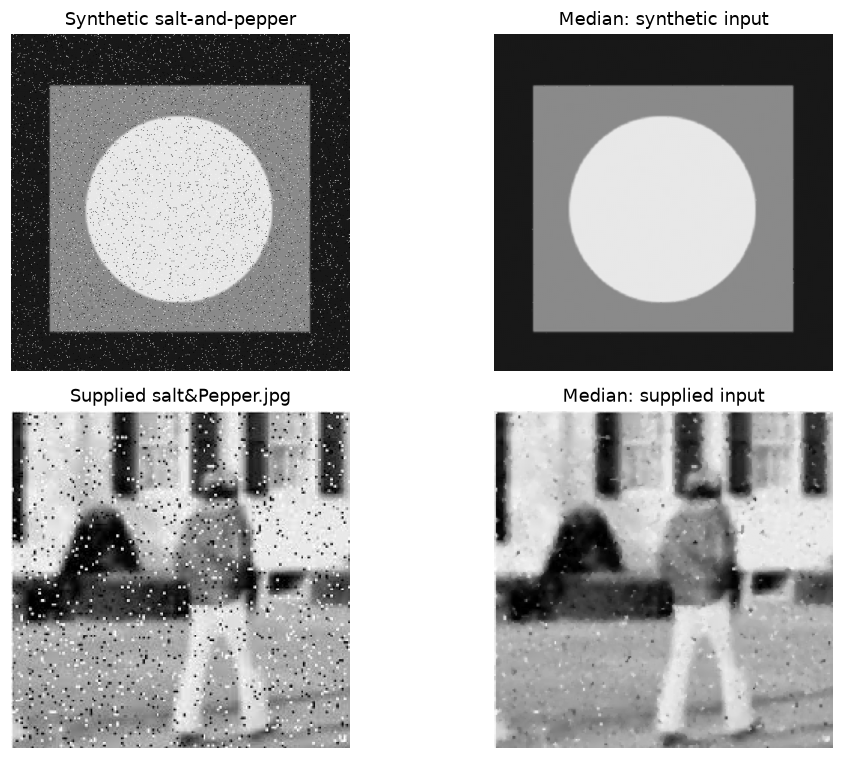

In [7]:
median_result = cv2.medianBlur(noisy['salt_pepper'], 3)
supplied_median = cv2.medianBlur(supplied_sp, 3)
show_images([noisy['salt_pepper'], median_result, supplied_sp, supplied_median],
            ['Synthetic salt-and-pepper', 'Median: synthetic input',
             'Supplied salt&Pepper.jpg', 'Median: supplied input'])

## B7. Maximum and minimum filters
I implement the maximum with dilation and the minimum with erosion, using a
3 x 3 window and reflected borders. Maximum filtering replaces dark pepper
impulses but expands bright regions. Minimum filtering replaces bright salt
impulses but expands dark regions.

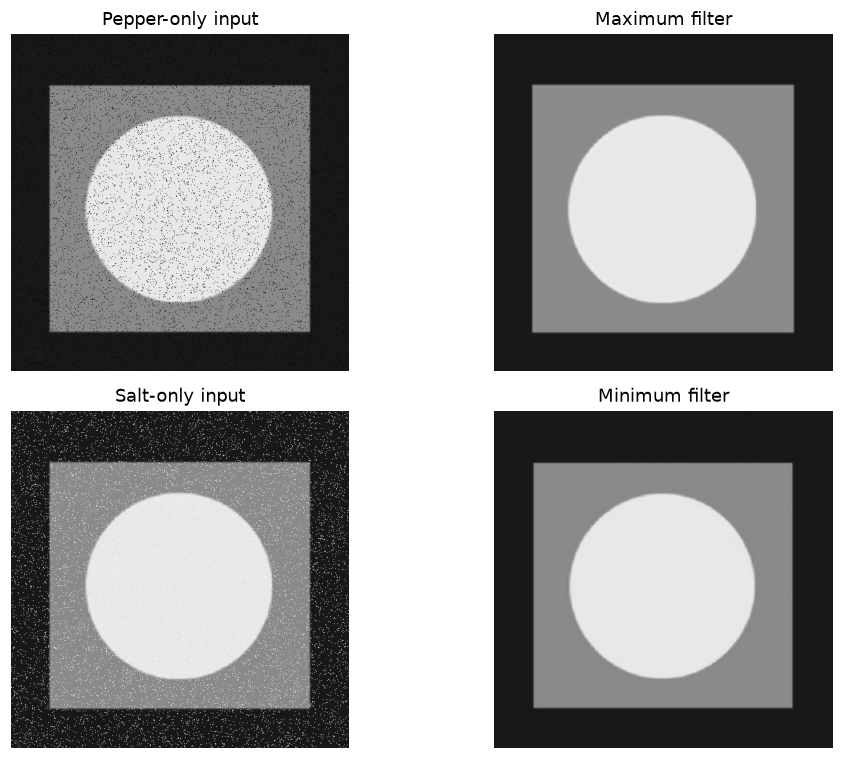

In [8]:
def max_filter(image, size=3):
    check_size(size)
    return cv2.dilate(image, np.ones((size, size), np.uint8), borderType=BORDER)

def min_filter(image, size=3):
    check_size(size)
    return cv2.erode(image, np.ones((size, size), np.uint8), borderType=BORDER)

show_images([pepper_only, max_filter(pepper_only), salt_only, min_filter(salt_only)],
            ['Pepper-only input', 'Maximum filter', 'Salt-only input', 'Minimum filter'])

## B8. Midpoint filter
I average the local minimum and maximum in floating point, then round and clip.
This avoids uint8 overflow. I demonstrate it on uniform noise; extreme impulses
can dominate this filter, so it is less suitable for salt-and-pepper noise.

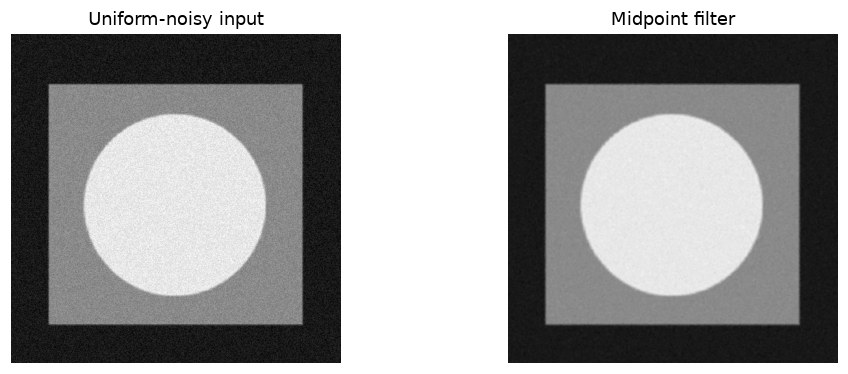

In [9]:
def midpoint_filter(image, kernel_size=3):
    high = max_filter(image, kernel_size).astype(np.float64)
    low = min_filter(image, kernel_size).astype(np.float64)
    return to_uint8((high + low) / 2)

show_images([noisy['uniform'], midpoint_filter(noisy['uniform'])],
            ['Uniform-noisy input', 'Midpoint filter'])

## B9. Comparison on every synthetic noise type
I measure mean squared error (MSE) and peak signal-to-noise ratio (PSNR)
against the supplied reference before adding noise. Lower MSE and higher PSNR
mean better agreement with that reference. They do not establish recovery of
an unknown clean scene. Every filter below uses a 3 x 3 window. I do not assign
reference-based scores to salt&Pepper.jpg because no matching clean image was supplied.

In [10]:
filters = {
    'Arithmetic': arithmetic_mean,
    'Geometric': geometric_mean_filter,
    'Harmonic': harmonic_mean_filter,
    'Contra +1.5': lambda x: contra_harmonic_mean(x, Q=1.5),
    'Contra -1.5': lambda x: contra_harmonic_mean(x, Q=-1.5),
    'Median': lambda x: cv2.medianBlur(x, 3),
    'Maximum': max_filter,
    'Minimum': min_filter,
    'Midpoint': midpoint_filter,
}

def metrics(image, target):
    error = image.astype(np.float64) - target.astype(np.float64)
    mse = float(np.mean(error ** 2))
    psnr = float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)
    return mse, psnr

all_results = {}
for noise_name, input_image in noisy.items():
    results = {name: function(input_image) for name, function in filters.items()}
    all_results[noise_name] = results
    print(f'\n{noise_name.upper():<16} {"MSE":>10} {"PSNR (dB)":>12}')
    for label, result in [('Noisy input', input_image), *results.items()]:
        mse, psnr = metrics(result, reference)
        print(f'{label:<16} {mse:10.2f} {psnr:12.2f}')
    best = min(results, key=lambda name: metrics(results[name], reference)[0])
    print('Lowest filtered MSE:', best)


GAUSSIAN                MSE    PSNR (dB)
Noisy input          534.94        20.85
Arithmetic            65.82        29.95
Geometric            265.32        23.89
Harmonic             285.22        23.58
Contra +1.5          324.01        23.03
Contra -1.5          313.15        23.17
Median               109.91        27.72
Maximum             1432.78        16.57
Minimum             1224.76        17.25
Midpoint             128.59        27.04
Lowest filtered MSE: Arithmetic

SALT_PEPPER             MSE    PSNR (dB)
Noisy input          946.85        18.37
Arithmetic           120.85        27.31
Geometric           3219.09        13.05
Harmonic            3213.70        13.06
Contra +1.5         2665.74        13.87
Contra -1.5         3213.94        13.06
Median                 0.48        51.36
Maximum             4633.13        11.47
Minimum             3236.58        13.03
Midpoint            1834.94        15.49
Lowest filtered MSE: Median



EXPONENTIAL             MSE    PSNR (dB)
Noisy input          185.80        25.44
Arithmetic           108.24        27.79
Geometric             93.86        28.41
Harmonic              83.60        28.91
Contra +1.5          180.01        25.58
Contra -1.5           76.15        29.31
Median                70.44        29.65
Maximum              891.39        18.63
Minimum               29.28        33.47
Midpoint             225.90        24.59
Lowest filtered MSE: Minimum

UNIFORM                 MSE    PSNR (dB)
Noisy input          133.28        26.88
Arithmetic            17.01        35.82
Geometric             22.46        34.62
Harmonic              39.51        32.16
Contra +1.5           44.11        31.69
Contra -1.5           62.87        30.15
Median                37.85        32.35
Maximum              316.64        23.13
Minimum              316.94        23.12
Midpoint              12.26        37.25
Lowest filtered MSE: Midpoint


## B10. Numerical checks and conclusion
I check all outputs, agreement of the two arithmetic implementations, constant
and zero images, known neighbourhood values, repeatability, and the special
contraharmonic cases. Filter choice depends on the noise: I use the median for
mixed impulses, compare averaging filters for Gaussian noise, and use the sign
of Q to target a single impulse type. The printed table records actual results
for these supplied images; smoothing can remove detail as well as noise.

In [11]:
assert np.allclose(mean_builtin_float, mean_manual_float, atol=1e-10)
for results in all_results.values():
    for result in results.values():
        assert result.shape == reference.shape
        assert result.dtype == np.uint8 and np.isfinite(result).all()
for value in [0, 80, 255]:
    constant = np.full((9, 9), value, np.uint8)
    for name, function in filters.items():
        assert np.all(function(constant) == value), (name, value)
sample = np.arange(1, 10, dtype=np.uint8).reshape(3, 3)
assert arithmetic_mean(sample)[1, 1] == 5
assert geometric_mean_filter(sample)[1, 1] == round(np.prod(sample.astype(float)) ** (1/9))
assert harmonic_mean_filter(sample)[1, 1] == round(9 / np.sum(1 / sample.astype(float)))
assert max_filter(sample)[1, 1] == 9 and min_filter(sample)[1, 1] == 1
assert midpoint_filter(sample)[1, 1] == 5
assert np.array_equal(contra_harmonic_mean(reference, Q=0), arithmetic_mean(reference))
assert np.array_equal(contra_harmonic_mean(reference, Q=-1), harmonic_mean_filter(reference))
repeat_rng = np.random.default_rng(2240001433)
for name in noise_names:
    assert np.array_equal(add_noise(reference, name, repeat_rng), noisy[name])
try:
    midpoint_filter(reference, 2)
except ValueError:
    pass
else:
    raise AssertionError('An even kernel must be rejected.')
print('Part B: all numerical, repeatability and image checks passed.')

Part B: all numerical, repeatability and image checks passed.
